In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cmocean.cm as cmo
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.feature import NaturalEarthFeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER
import dask
import glob
from dask.distributed import Client, progress

import sys
sys.path.append('/home/561/nm5072/MHW_sandbox')
import bipolarMhwToolBox as MHW

%matplotlib inline

In [2]:
from datetime import datetime

now = datetime.now()
print(now.strftime("%H:%M:%S"))

13:21:41


In [3]:
client = Client(processes=True, threads_per_worker=1,memory_limit="32GB")
client

/g/data/xp65/public/apps/med_conda/envs/analysis3_edge-25.06/lib/python3.11/site-packages/distributed/node.py:187: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 32801 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/32801/status,
Dashboard: /proxy/32801/status,Workers: 14
Total threads: 14,Total memory: 417.23 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:40075,Workers: 0
Dashboard: /proxy/32801/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:38931,Total threads: 1
Dashboard: /proxy/38403/status,Memory: 29.80 GiB
Nanny: tcp://127.0.0.1:44603,


In [4]:
# 1. Load the Severity Zarr (Computed in the previous step)
# We use consolidated=True for faster loading of metadata
input_path = '/scratch/m35/nm5072/oisst_1988-2018_severity_full.zarr'
ds_sev = xr.open_zarr(input_path, consolidated=True)

# Check chunking - it should be (10958, 1, 90, 90) or similar
print(f"Input chunks: {ds_sev.chunks}")

/g/data/xp65/public/apps/med_conda/envs/analysis3_edge-25.06/lib/python3.11/site-packages/xarray/backends/plugins.py:110: RuntimeWarning: Engine 'cfradial1' loading failed:
/g/data/xp65/public/apps/med_conda/envs/analysis3_edge-25.06/lib/python3.11/site-packages/h5py/../../../././libucc.so.1: undefined symbol: ucs_config_doc_nop
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)
/g/data/xp65/public/apps/med_conda/envs/analysis3_edge-25.06/lib/python3.11/site-packages/xarray/backends/plugins.py:110: RuntimeWarning: Engine 'datamet' loading failed:
/g/data/xp65/public/apps/med_conda/envs/analysis3_edge-25.06/lib/python3.11/site-packages/h5py/../../../././libucc.so.1: undefined symbol: ucs_config_doc_nop
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)
/g/data/xp65/public/apps/med_conda/envs/analysis3_edge-25.06/lib/python3.11/site-packages/xarray/backends/plugins.py:110: RuntimeWarning: Engine 'furuno' loading failed:
/g/data/xp65/publi

Input chunks: Frozen({'time': (10958,), 'zlev': (1,), 'lat': (90, 90, 90, 90, 90, 90, 90, 90), 'lon': (90, 90, 90, 90, 90, 90, 90, 90, 90, 90, 90, 90, 90, 90, 90, 90)})


/g/data/xp65/public/apps/med_conda/envs/analysis3_edge-25.06/lib/python3.11/site-packages/xarray/backends/plugins.py:110: RuntimeWarning: Engine 'radolan' loading failed:
/g/data/xp65/public/apps/med_conda/envs/analysis3_edge-25.06/lib/python3.11/site-packages/h5py/../../../././libucc.so.1: undefined symbol: ucs_config_doc_nop
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)
/g/data/xp65/public/apps/med_conda/envs/analysis3_edge-25.06/lib/python3.11/site-packages/xarray/backends/plugins.py:110: RuntimeWarning: Engine 'rainbow' loading failed:
/g/data/xp65/public/apps/med_conda/envs/analysis3_edge-25.06/lib/python3.11/site-packages/h5py/../../../././libucc.so.1: undefined symbol: ucs_config_doc_nop
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


In [5]:
# 2. Calculate MHW Metrics
# The function expects 'ds' to contain 'ssta' and 'severity'.
# Since we used keep_ssta=True previously, ds_sev has both.
# maxEvt=200 allows for up to 200 events per pixel over the 30-year period.
print("Defining MHW computation graph...")

ds_metrics = MHW.calculate_MHWs_metrics(ds_sev, maxEvt=400)

Defining MHW computation graph...


In [6]:
# 3. Clean up Dimensions (Optional but recommended)
# The output will have dims (variable, event, zlev, lat, lon).
# If zlev is 1, we can squeeze it out to make the file smaller/cleaner.
if 'zlev' in ds_metrics.dims:
    ds_metrics = ds_metrics.squeeze('zlev')

In [ ]:
# 4. Save Metrics to Disk
# We save to a new Zarr file. 
output_path = '/scratch/m35/nm5072/oisst_1988-2018_mhw_events.zarr'

print(f"Starting computation. Saving to: {output_path}")

# This will trigger the actual computation.
# Since the input is chunked by time=-1, Dask will process this 
# one spatial tile at a time (embarrassingly parallel).

ds_metrics.to_zarr(output_path, mode='w', consolidated=True)

print("MHW Event detection complete.")

Starting computation. Saving to: /scratch/m35/nm5072/oisst_1988-2018_mhw_events.zarr


In [ ]:
# started 12:30

In [ ]:
now = datetime.now()
print(now.strftime("%H:%M:%S"))

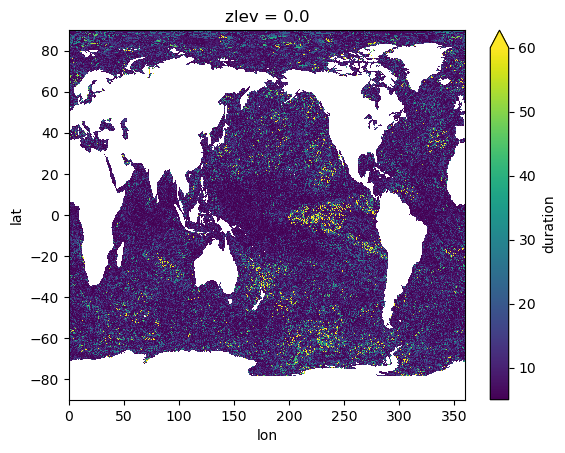

In [16]:
# Example: Plot the duration of the 1st, 2nd, and 3rd strongest events at a location
ds_results = xr.open_zarr('/scratch/m35/nm5072/oisst_1988-2018_mhw_events.zarr')

# Extract specific variables
duration = ds_results['duration']  # Shape: (event, lat, lon)
intensity = ds_results['intensity_max']

# Select the strongest event (if sorted) or just the first chronologically
# Note: The toolbox returns events chronologically.
first_event_duration = duration.isel(event=12)
first_event_duration.plot(vmin=5, vmax=60)

### Save out boolean MHW mask (runs very fast ~30 seconds)

In [18]:
# 2. Define the Logic for True MHW Mask
# This mirrors the logic in your toolbox (minDuration=5, maxGap=2)
# but returns a 1D boolean array (time) instead of event indices.

def get_true_mhw_mask_1d(severity_timeseries, minDuration=5, maxGap=2):
    """
    Returns an int8 array (0 or 1) identifying strict MHW days.
    Fills gaps <= maxGap and filters events < minDuration.
    """
    # 1. Identify raw exceedance
    boolSever = severity_timeseries > 1
    
    # Initialize output mask (all zeros)
    mask_out = np.zeros_like(boolSever, dtype='int8')
    
    # Check if there are any hot days at all
    ia = np.asarray(boolSever)
    if not np.any(ia):
        return mask_out

    # 2. Find runs (start and end indices)
    n = len(ia)
    y = ia[1:] != ia[:-1] # Find changes from T->F or F->T
    i = np.append(np.where(y), n - 1)
    l_cont = np.diff(np.append(-1, i))
    run_ends = i
    run_starts = i - l_cont + 1

    # Filter to keep only True runs
    run_mask = ia[run_ends]
    i_start = run_starts[run_mask]
    i_end   = run_ends[run_mask]

    # 3. Apply Min Duration (First Pass)
    # Note: Hobday definition usually bridges gaps FIRST, then checks duration.
    # However, standard code often filters short spikes, bridges, then filters again.
    # We will follow the logic standard in your toolbox:
    # (Filter -> Merge -> Filter is implicit if we merge based on distance)
    
    # Let's stick to the toolbox logic you provided exactly:
    # It enforces minDuration BEFORE merging gaps? 
    # Actually, looking at your file: it enforces duration, THEN merges.
    keep = (i_end - i_start + 1) >= minDuration
    i_start = i_start[keep]
    i_end   = i_end[keep]

    # 4. Merge Gaps
    if len(i_start) > 1 and maxGap > 0:
        # Distance between current start and previous end
        gap_len = i_start[1:] - i_end[:-1] - 1
        indGap = np.where(gap_len <= maxGap)[0]
        
        # If we bridge gaps, we effectively delete the "end" of the first
        # and the "start" of the second.
        i_start = np.delete(i_start, indGap + 1)
        i_end   = np.delete(i_end,   indGap)

    # 5. Re-check Duration (Optional, but good practice after merging)
    # (If merging two 2-day events over a 1-day gap, total is 5 days -> valid)
    # But since your toolbox filtered BEFORE merging, we leave it as is to match your other files.

    # 6. Paint the mask
    # We loop through the identified start/ends and set those days to 1
    for s, e in zip(i_start, i_end):
        mask_out[s : e+1] = 1
        
    return mask_out

# 3. Apply to the full dataset using Dask
# input_core_dims=[['time']] means "give the function the whole time array for a pixel at once"
print("Setting up computation graph...")

true_mhw_mask = xr.apply_ufunc(
    get_true_mhw_mask_1d,
    ds_sev['severity'],
    kwargs={'minDuration': 5, 'maxGap': 2},
    input_core_dims=[['time']],
    output_core_dims=[['time']],
    vectorize=True,         # Loop over lat/lon automatically
    dask='parallelized',    # Use Dask workers
    output_dtypes=['int8']  # Output is integer (0/1)
)

# 4. Add Metadata
true_mhw_mask.name = 'mhw_strict_mask'
true_mhw_mask.attrs['description'] = '1 if True MHW (Duration>=5, Gap<=2), 0 otherwise'

# 5. Save to Disk
output_path = '/scratch/m35/nm5072/oisst_1988-2018_mhw_strict_mask.zarr'
print(f"Saving True MHW mask to {output_path}...")


true_mhw_mask.to_dataset().to_zarr(output_path, mode='w', consolidated=True)

print("Done.")

Setting up computation graph...
Saving True MHW mask to /scratch/m35/nm5072/oisst_1988-2018_mhw_strict_mask.zarr...
Done.
